In [1]:
from stl import mesh
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists
import open3d as o3d

from tests.utils import find_neighbours_with_knn, return_rings

C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


found ring 1 with 715 points.
found ring 2 with 715 points.
found ring 1 with 543 points.
found ring 2 with 535 points.
found ring 1 with 783 points.
found ring 2 with 765 points.
found ring 1 with 835 points.
found ring 2 with 833 points.
found ring 1 with 487 points.
found ring 2 with 458 points.
found ring 1 with 349 points.
found ring 2 with 274 points.


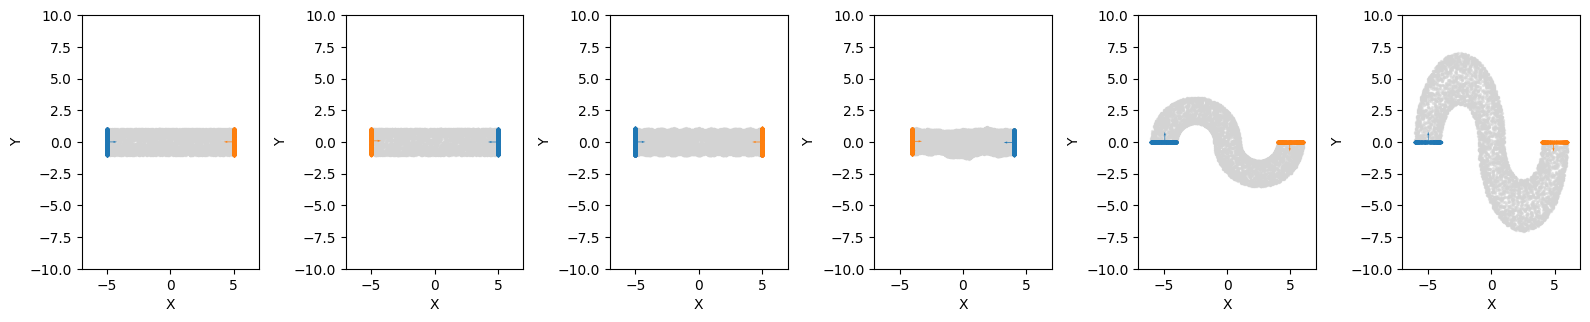

In [12]:
basenames = ["straight_cylinder_L10_R1",
             "straight_elliptical_prism_L10_R1_R05",
             "straight_cylinder_L10_R_variable",
             "straight_cylinder_L8_R1_stochastic",
             "sinuous_D5_r_1",
             "extra_sinuous_D5_r_1"]

fig = plt.figure(figsize = (16, 5))

for c, basename in enumerate(basenames):

    ax = fig.add_subplot(1, len(basenames), c+1)

    mesh_filepath = f"./tests/meshes/{basename}.stl"
    meshdata = mesh.Mesh.from_file(mesh_filepath)

    ADJACENT_TRIANGLES_PATH = f"./tests/meshes/{basename}_adjacent_triangles.txt"
    keep = True

    if exists(ADJACENT_TRIANGLES_PATH) and keep:
        adjacent_triangles = np.loadtxt(ADJACENT_TRIANGLES_PATH).astype(int)
    else:
        adjacent_triangles = find_neighbours_with_knn(meshdata)
        np.savetxt(ADJACENT_TRIANGLES_PATH,adjacent_triangles, fmt="%.1d")
    out = return_rings(meshdata, adjacent_triangles)

    ax.scatter(*meshdata.centroids[::100, [0,1]].T, color = "lightgrey", alpha = 0.5, s = 2)
    ax.scatter(*out["ring1"][:, [0,1]].T, c="C0", s = 2, label = "ring 1")
    ax.scatter(*out["ring2"][:, [0,1]].T, c="C1", s = 2, label = "ring 2")
    ax.quiver(*out["P1"][[0,1]] ,*out["nP1"][[0,1]],color = "C0", width = 0.004)
    ax.quiver(*out["P2"][[0,1]] ,*out["nP2"][[0,1]],color = "C1", width = 0.004)

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_xlim(-7,7)
    ax.set_ylim(-10,10)
    ax.set_aspect("equal")
    #ax.legend()
plt.tight_layout()
plt.savefig("./tests/outputs/finding_inlet_outlet_rings.png", dpi = 300)
plt.show()